# Loan Approval ML Project

**📝 Problem Statement**

**Step 1: Import Libraries**

In [31]:
#system and data manipulation
import joblib
import numpy as np
import pandas as pd

#visualization
import matplotlib.pyplot as plt
import seaborn as sns

#preprocessing 
from sklearn.model_selection import RandomizedSearchCV, cross_val_score, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler

#feature selection
from sklearn.feature_selection import VarianceThreshold

#classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

#metrics
from sklearn.metrics import accuracy_score,f1_score, roc_auc_score, precision_score, recall_score



**Step 2: Load Dataset**

In [3]:
df = pd.read_json('loan_approval_dataset.json')

**Step 3: Understand Your Data (EDA)**

In [4]:
print("\n[First 5 Rows Preview]:\n")
df.head()


[First 5 Rows Preview]:



,Id,Income,Age,Experience,Married/Single,House_Ownership,Car_Ownership,Profession,CITY,STATE,CURRENT_JOB_YRS,CURRENT_HOUSE_YRS,Risk_Flag
0,1,1303834,23,3,single,rented,no,Mechanical_engineer,Rewa,Madhya_Pradesh,3,13,0
1,2,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
2,3,3991815,66,4,married,rented,no,Technical_writer,Alappuzha,Kerala,4,10,0
3,4,6256451,41,2,single,rented,yes,Software_Developer,Bhubaneswar,Odisha,2,12,1
4,5,5768871,47,11,single,rented,no,Civil_servant,Tiruchirappalli[10],Tamil_Nadu,3,14,1


In [5]:
print(f"\n[Dataset Dimensions (Rows, Columns)]: {df.shape}")


[Dataset Dimensions (Rows, Columns)]: (252000, 13)


In [6]:
df.columns

Index(['Id', 'Income', 'Age', 'Experience', 'Married/Single',
       'House_Ownership', 'Car_Ownership', 'Profession', 'CITY', 'STATE',
       'CURRENT_JOB_YRS', 'CURRENT_HOUSE_YRS', 'Risk_Flag'],
      dtype='str')

In [7]:
df.nunique()

Id                   252000
Income                41920
Age                      59
Experience               21
Married/Single            2
House_Ownership           3
Car_Ownership             2
Profession               51
CITY                    317
STATE                    29
CURRENT_JOB_YRS          15
CURRENT_HOUSE_YRS         5
Risk_Flag                 2
dtype: int64

In [8]:
df.dtypes

Id                   int64
Income               int64
Age                  int64
Experience           int64
Married/Single         str
House_Ownership        str
Car_Ownership          str
Profession             str
CITY                   str
STATE                  str
CURRENT_JOB_YRS      int64
CURRENT_HOUSE_YRS    int64
Risk_Flag            int64
dtype: object

In [9]:
print("\n[Data Types and Structural Check]:")
df.info()


[Data Types and Structural Check]:
<class 'pandas.DataFrame'>
Index: 252000 entries, 0 to 251999
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   Id                 252000 non-null  int64
 1   Income             252000 non-null  int64
 2   Age                252000 non-null  int64
 3   Experience         252000 non-null  int64
 4   Married/Single     252000 non-null  str  
 5   House_Ownership    252000 non-null  str  
 6   Car_Ownership      252000 non-null  str  
 7   Profession         252000 non-null  str  
 8   CITY               252000 non-null  str  
 9   STATE              252000 non-null  str  
 10  CURRENT_JOB_YRS    252000 non-null  int64
 11  CURRENT_HOUSE_YRS  252000 non-null  int64
 12  Risk_Flag          252000 non-null  int64
dtypes: int64(7), str(6)
memory usage: 37.9 MB


In [10]:
print("\n[Descriptive Statistical Summary]:\n")
df.describe()


[Descriptive Statistical Summary]:



,Id,Income,Age,Experience,CURRENT_JOB_YRS,CURRENT_HOUSE_YRS,Risk_Flag
count,252000.000000,2.520000e+05,252000.000000,252000.000000,252000.000000,252000.000000,252000.000000
mean,126000.500000,4.997117e+06,49.954071,10.084437,6.333877,11.997794,0.123000
std,72746.278255,2.878311e+06,17.063855,6.002590,3.647053,1.399037,0.328438
min,1.000000,1.031000e+04,21.000000,0.000000,0.000000,10.000000,0.000000
25%,63000.750000,2.503015e+06,35.000000,5.000000,3.000000,11.000000,0.000000
50%,126000.500000,5.000694e+06,50.000000,10.000000,6.000000,12.000000,0.000000
75%,189000.250000,7.477502e+06,65.000000,15.000000,9.000000,13.000000,0.000000
max,252000.000000,9.999938e+06,79.000000,20.000000,14.000000,14.000000,1.000000


In [11]:
# Target Variable Analysis (Fraud Class Balance Profile)
print("\n[Target Variable Value Counts (0 = Legit, 1 = Fraud)]:")
print(df['Risk_Flag'].value_counts())


[Target Variable Value Counts (0 = Legit, 1 = Fraud)]:
Risk_Flag
0    221004
1     30996
Name: count, dtype: int64


**Step 4: Data Cleaning**

In [12]:
# 1. Remove Duplicates
print(f"Duplicate rows identified: {df.duplicated().sum()}")
df = df.drop_duplicates()

Duplicate rows identified: 0


In [13]:
# 2. Remove Unwanted Columns
df.drop(columns=['Id'], inplace=True)

In [14]:
# 2. Check for Missing Values 
print("Missing values per parameter:\n", df.isnull().sum())

Missing values per parameter:
 Income               0
Age                  0
Experience           0
Married/Single       0
House_Ownership      0
Car_Ownership        0
Profession           0
CITY                 0
STATE                0
CURRENT_JOB_YRS      0
CURRENT_HOUSE_YRS    0
Risk_Flag            0
dtype: int64


In [15]:
# 4. Fix Data Types
# No need

In [16]:
# 5. Fix proper col names
df = df.rename(columns={
    'Age':'age', 
    'Experience':'experience', 
    'Married/Single':'married_status', 
    'House_Ownership':'house_ownership',
    'Car_Ownership':'car_ownership', 
    'Profession':'profession', 
    'CITY':'city', 
    'STATE':'state', 
    'CURRENT_JOB_YRS':'current_job_yrs',
    'CURRENT_HOUSE_YRS':'current_house_yrs', 
    'Risk_Flag':'risk_flag'
})

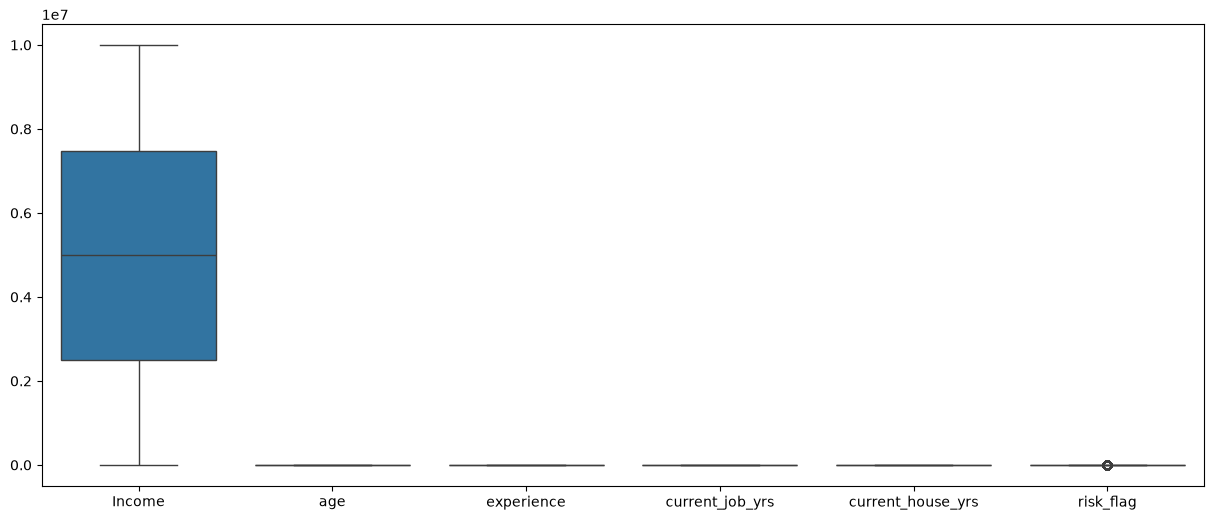

In [17]:
# # 6. Remove outliers

plt.figure(figsize=(15,6))
sns.boxplot(df[df.select_dtypes(include=['int','float']).columns.tolist()])
plt.show()

**Step 5: Feature Engineering**

In [18]:
# Ratio of current job tenure to total work experience
df['job_stability_ratio'] = df['current_job_yrs'] / (df['experience'] + 1)

# Earning power relative to career length
df['income_per_experience_yr'] = df['Income'] / (df['experience'] + 1)

# Assumes 'car_ownership' and 'house_ownership' are encoded as 1 (Yes/Owned) and 0 (No/Rented)
# If they are strings, encode them first!
df['total_assets_count'] = (df['car_ownership'] == 'yes').astype(int) + (df['house_ownership'] == 'owned').astype(int)

In [19]:
df['risk_flag'].value_counts()

risk_flag
0    221004
1     30996
Name: count, dtype: int64

**Step 6: Data Visualization**

Univariate:

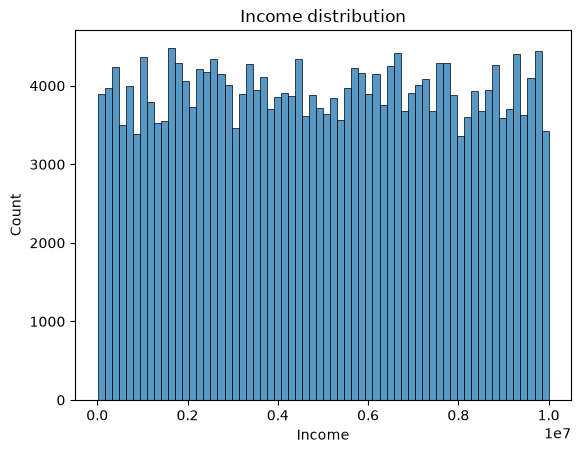

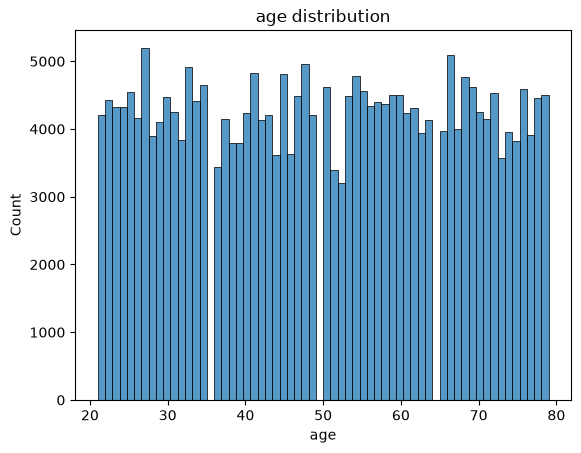

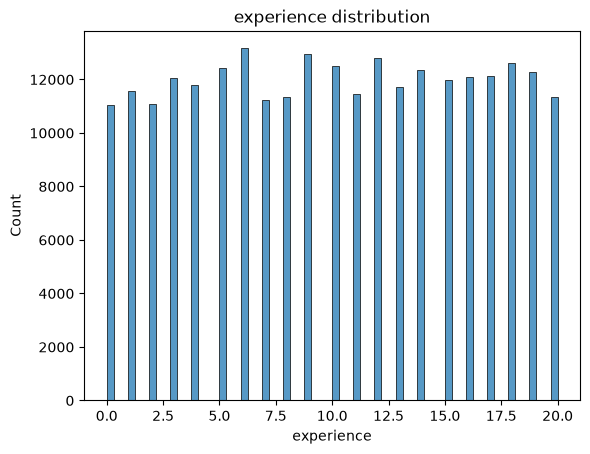

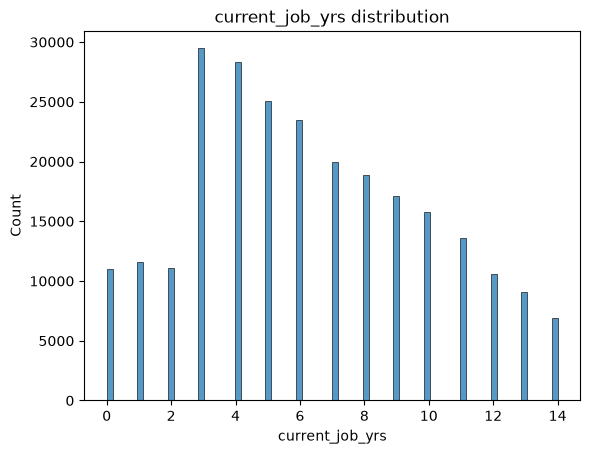

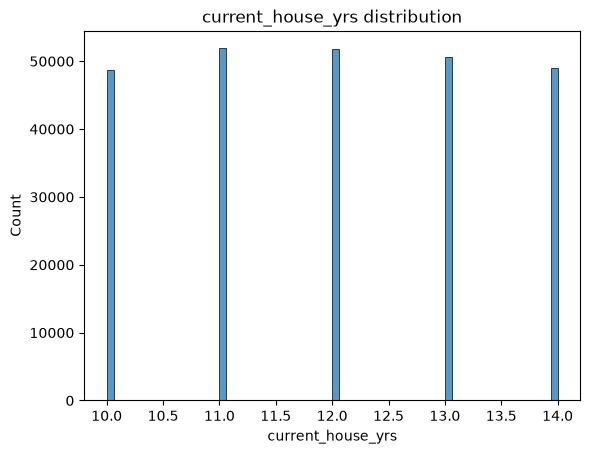

In [20]:
numeric = ['Income', 'age', 'experience','current_job_yrs','current_house_yrs']

for n in numeric:
    sns.histplot(data=df,x=n)
    plt.title(f"{n} distribution")
    plt.show()

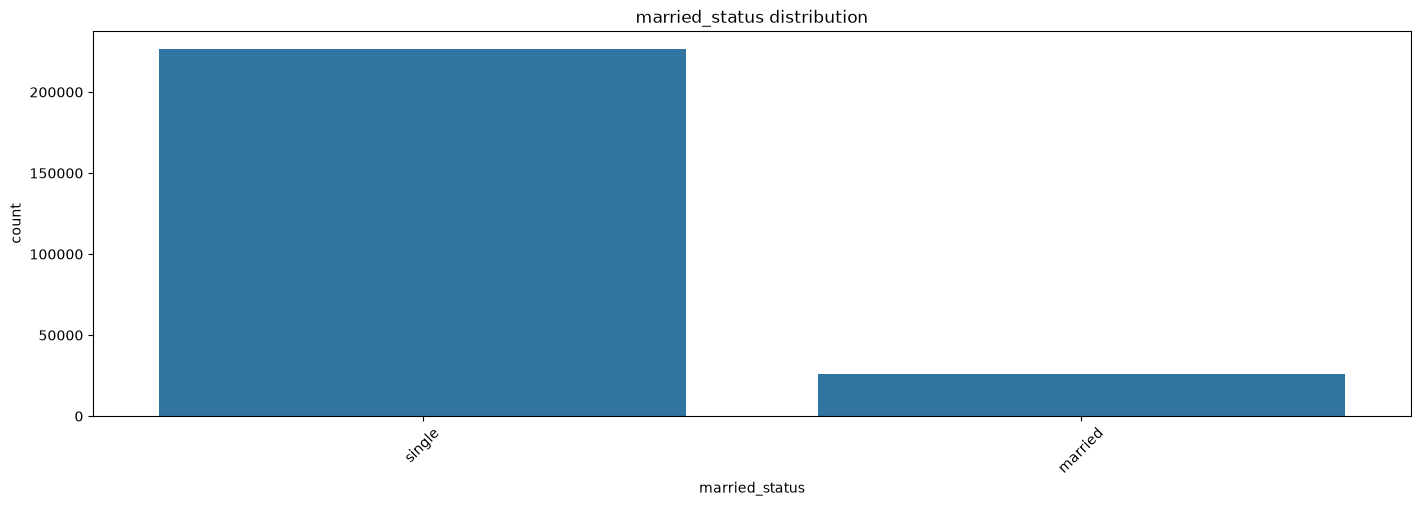

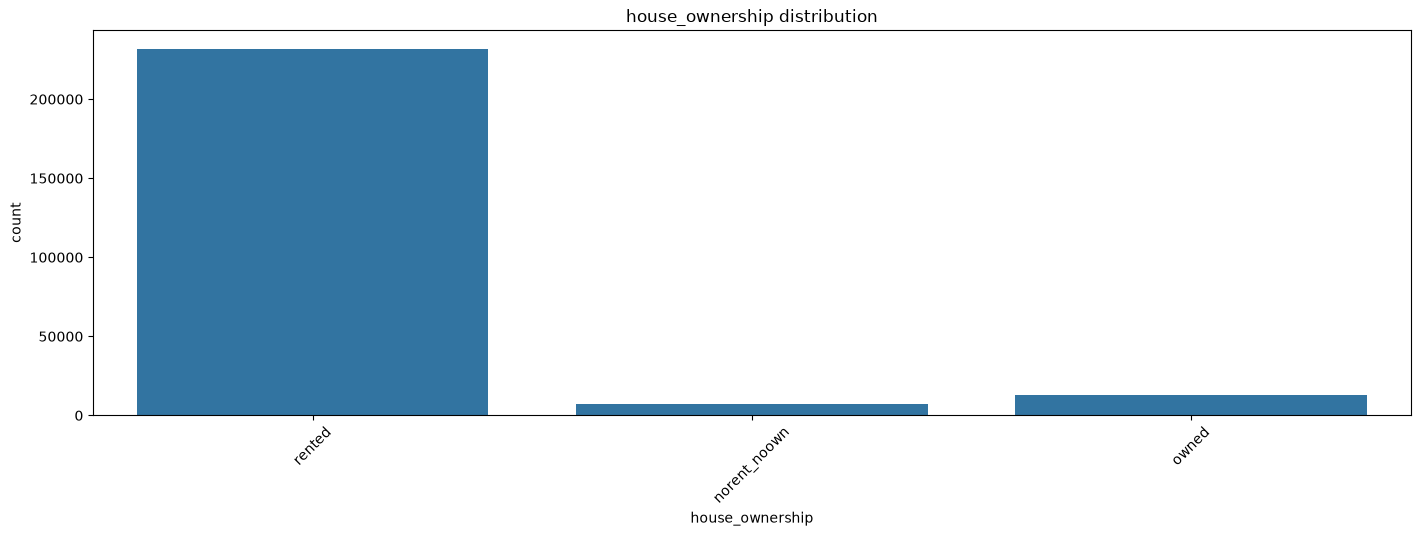

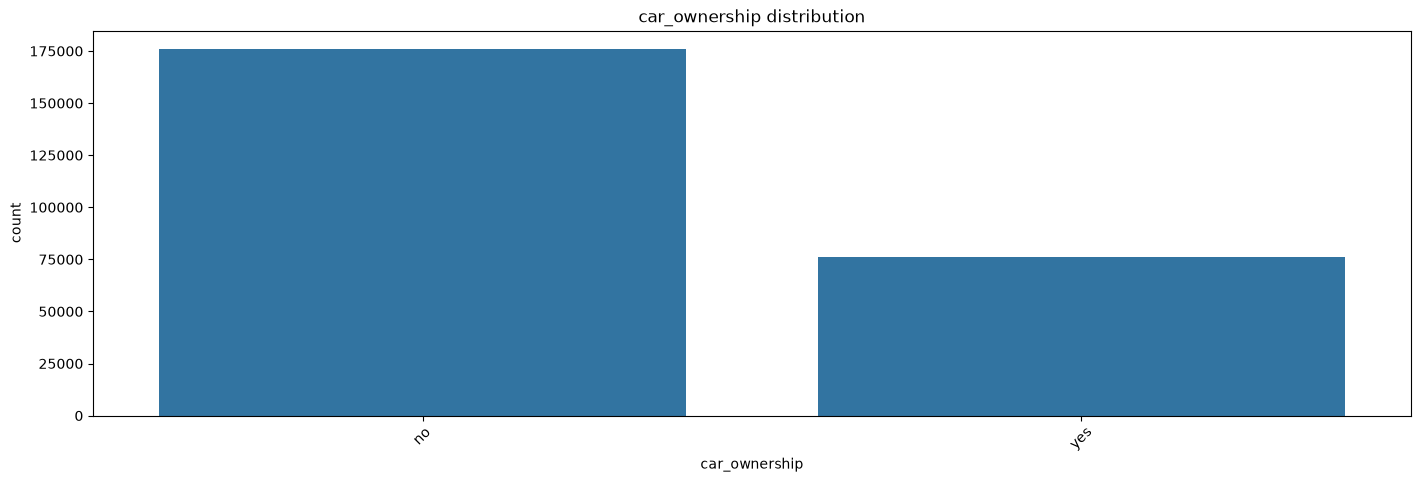

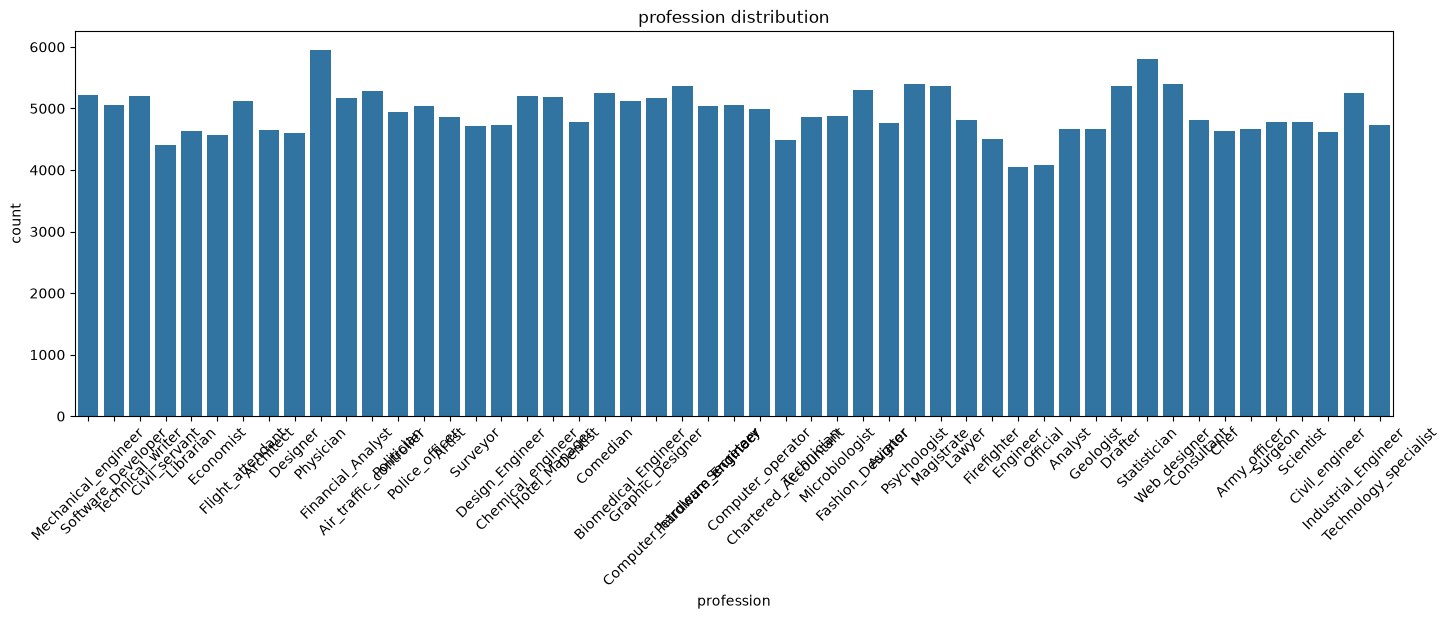

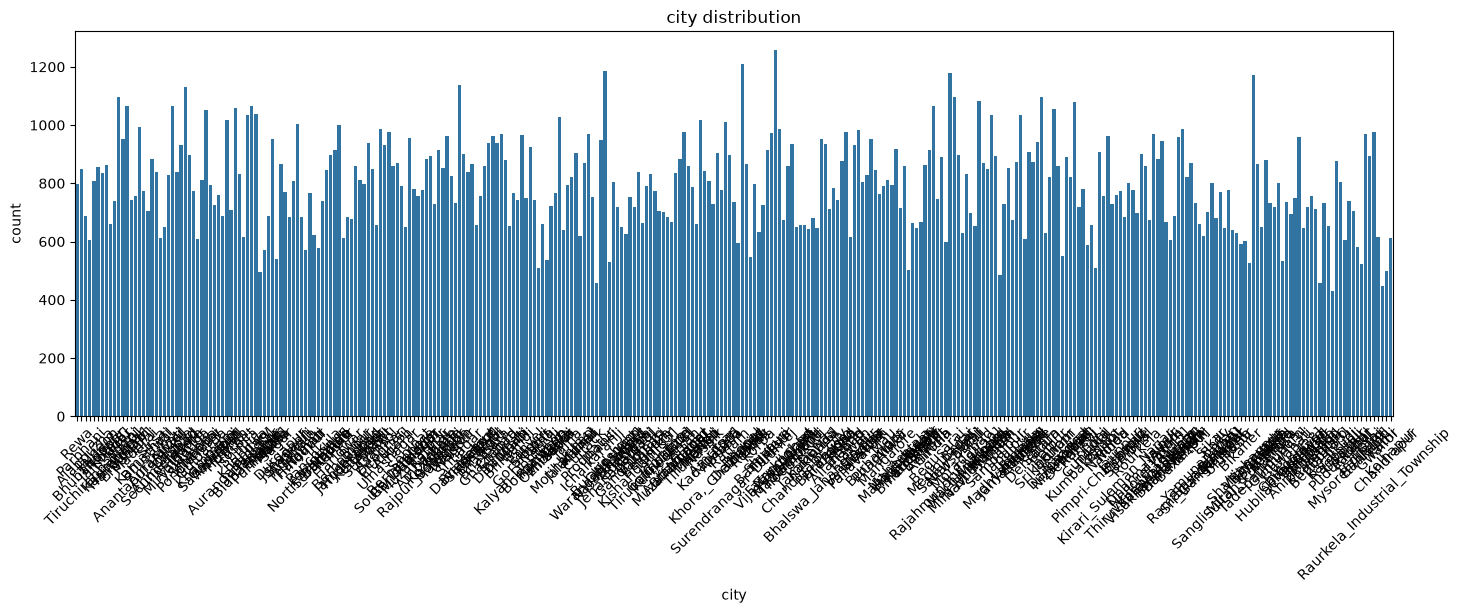

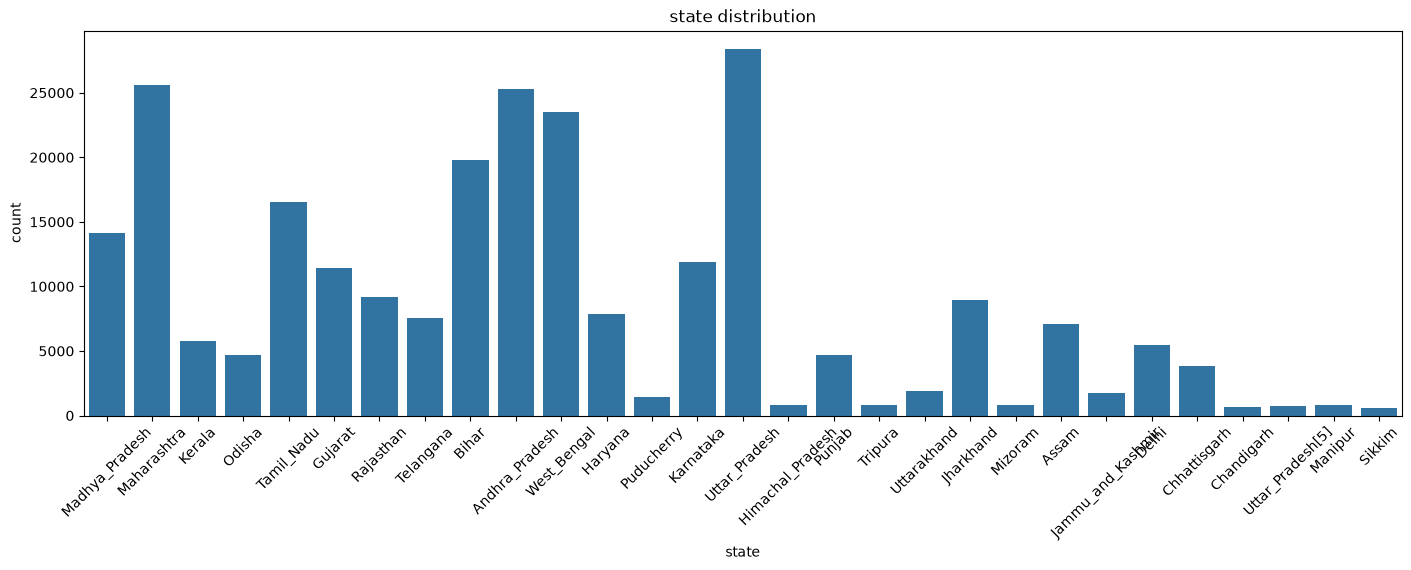

In [21]:
numeric = ['married_status', 'house_ownership', 'car_ownership','profession','city','state']

for n in numeric:
    plt.figure(figsize=(17,5))
    sns.countplot(data=df,x=n)
    plt.title(f"{n} distribution")
    plt.xticks(rotation=45)
    plt.show()

Bivariate & Multivariate:

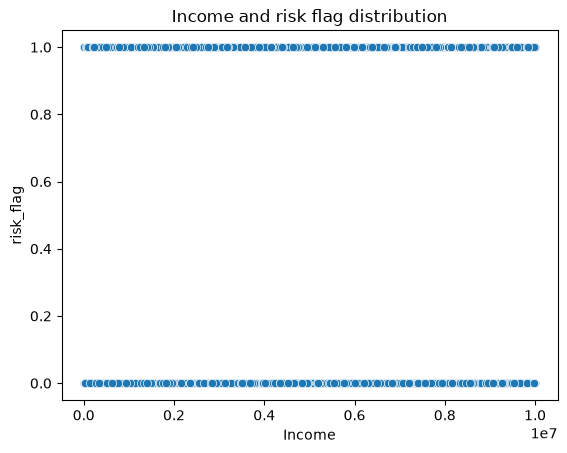

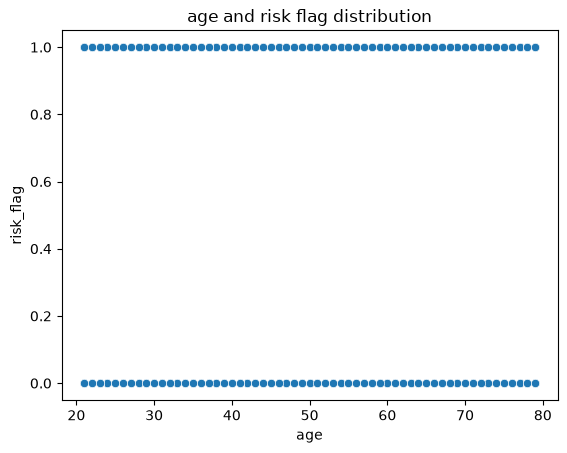

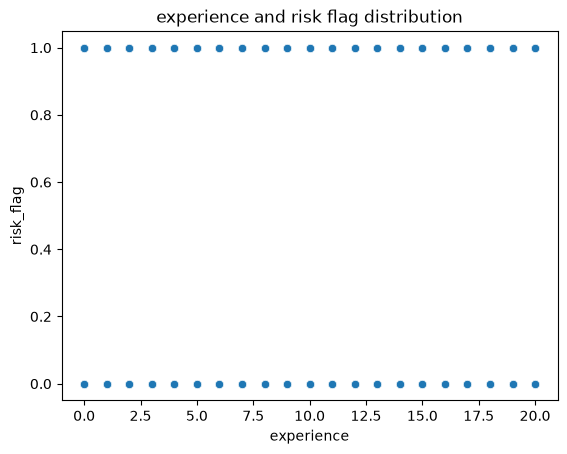

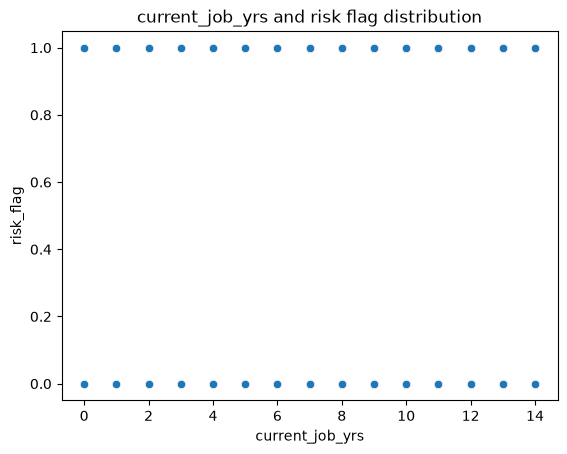

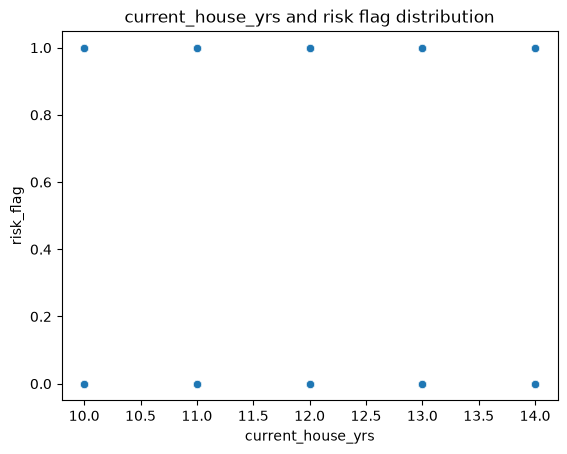

In [22]:
numeric = ['Income', 'age', 'experience','current_job_yrs','current_house_yrs']

for n in numeric:
    sns.scatterplot(data=df,x=n, y='risk_flag')
    plt.title(f"{n} and risk flag distribution")
    plt.show()

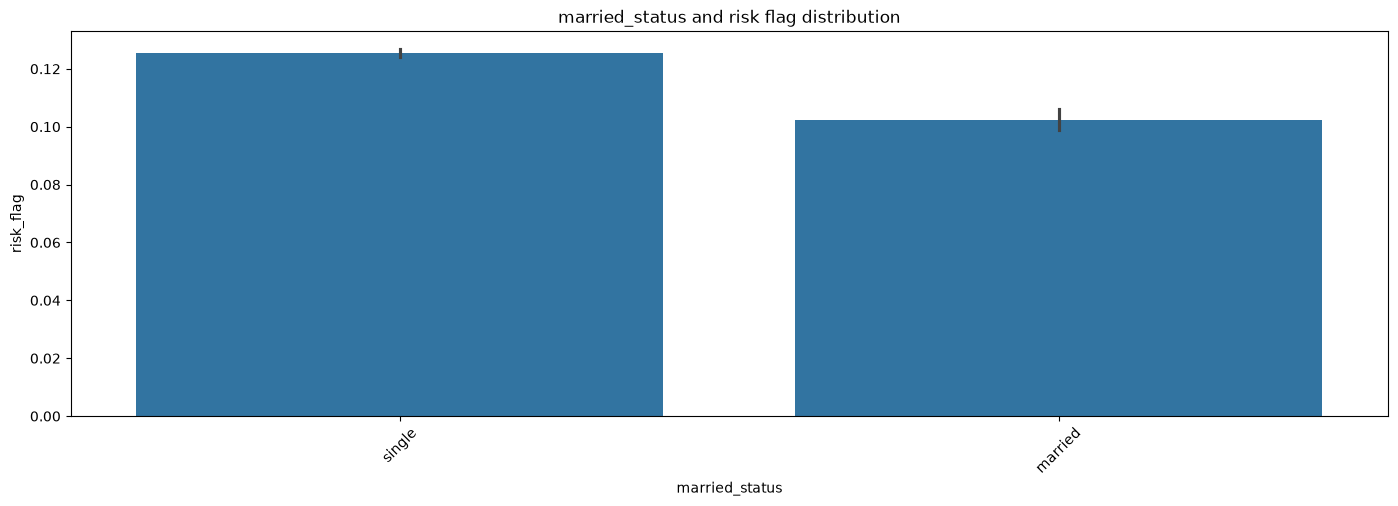

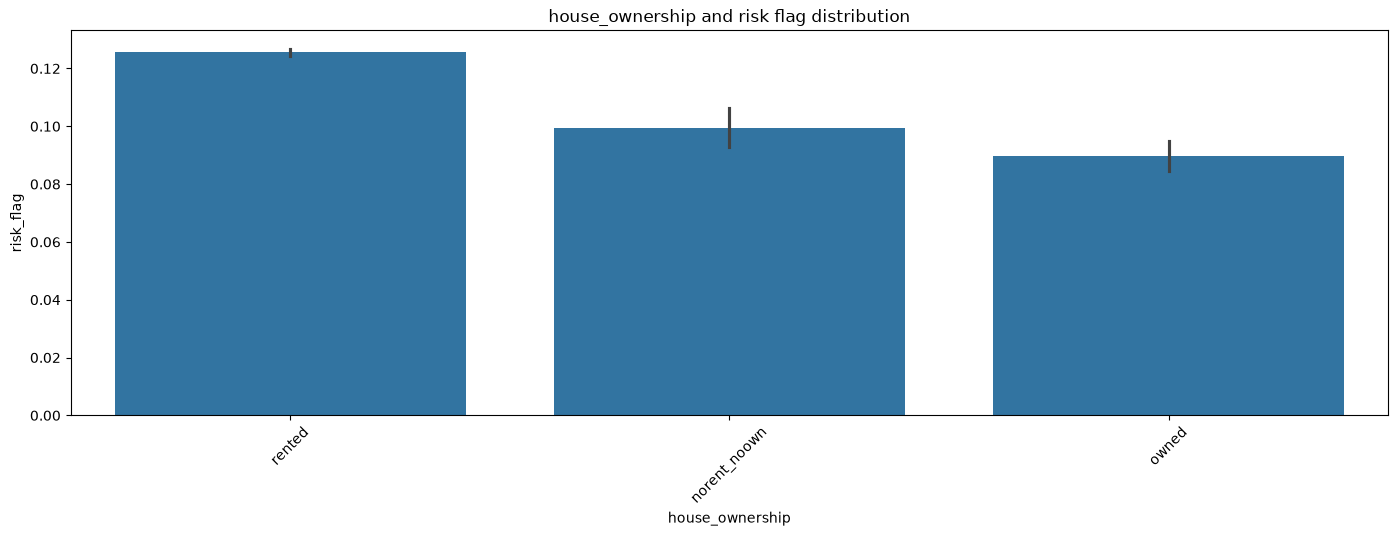

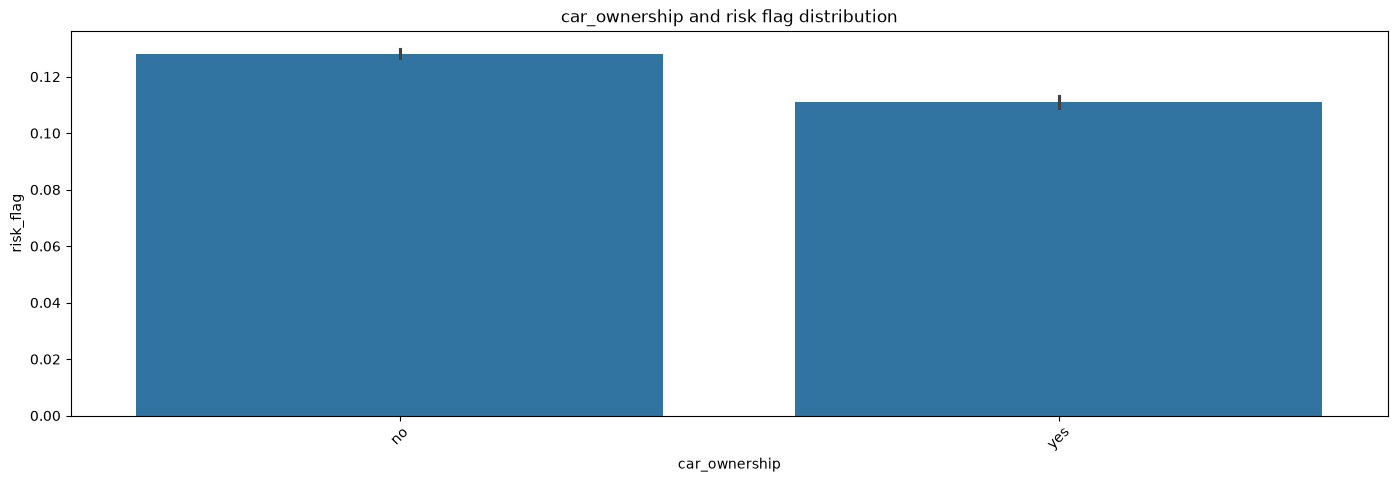

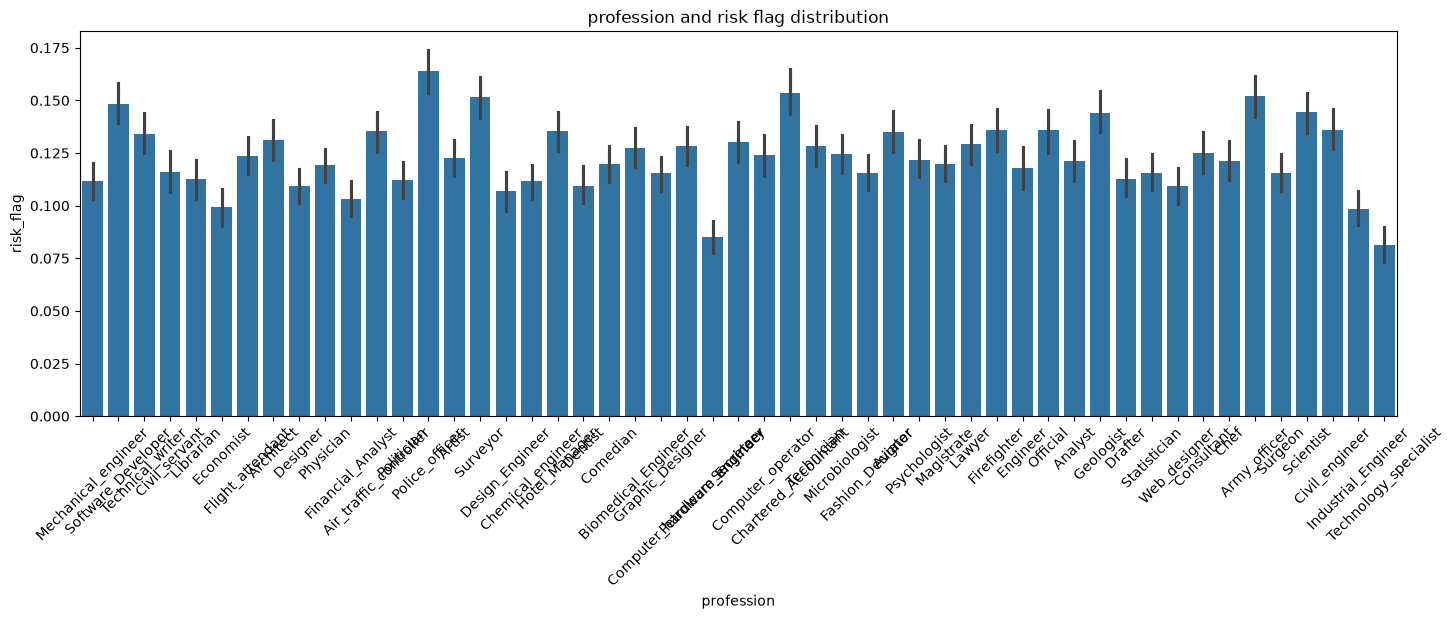

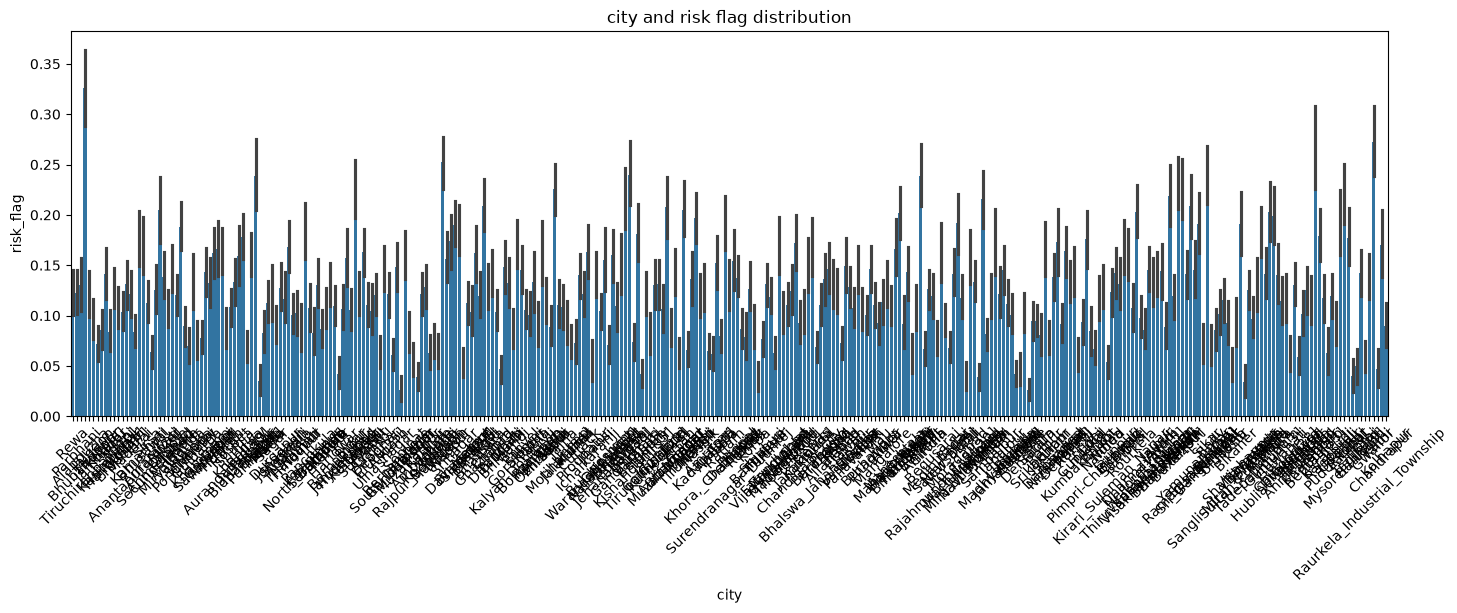

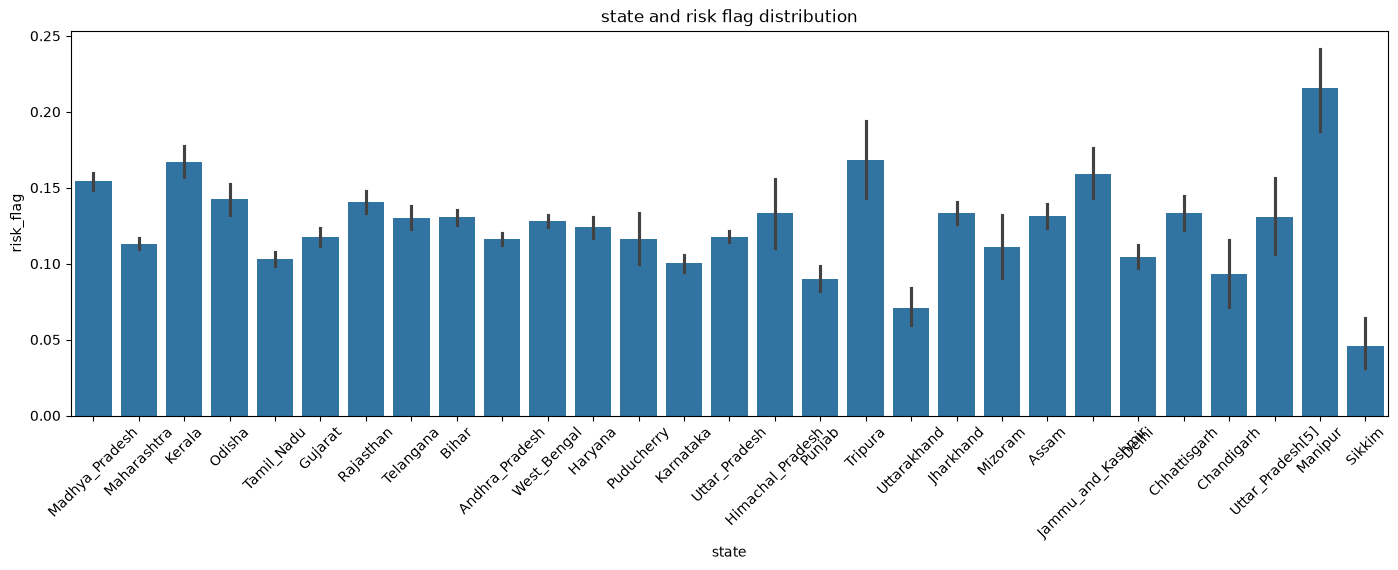

In [23]:
numeric = ['married_status', 'house_ownership', 'car_ownership','profession','city','state']

for n in numeric:
    plt.figure(figsize=(17,5))
    sns.barplot(data=df,x=n, y='risk_flag')
    plt.title(f"{n} and risk flag distribution")
    plt.xticks(rotation=45)
    plt.show()

Correlation analysis:

Text(0.5, 1.0, 'Correlation Matrix')

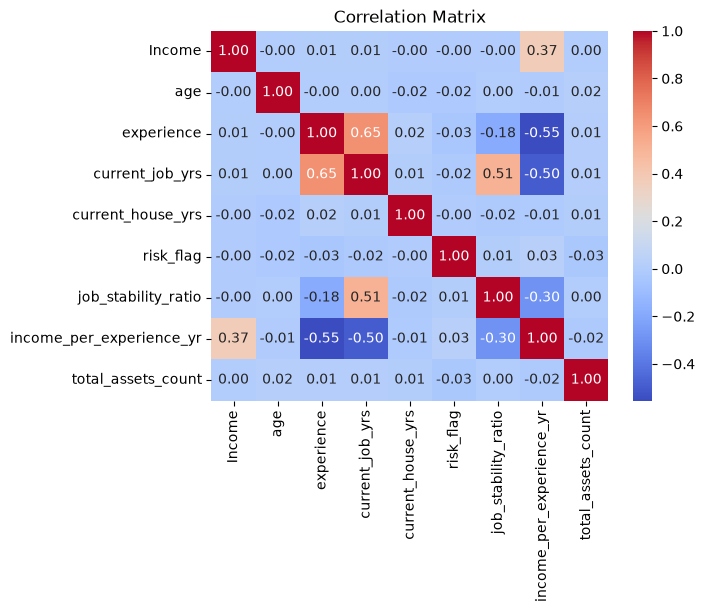

In [24]:
sns.heatmap(df.corr(numeric_only=True),annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')

**Step 7: Define Features (X) and Target (y)**

In [25]:
X = df.drop(columns=['risk_flag'])
y = df['risk_flag']

num_cols = df.select_dtypes(include=[int,float]).drop(columns=['risk_flag']).columns.tolist()
cat_cols = df.select_dtypes(include=[str]).columns.tolist()

**Step 8: Train-Test Split**

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print(f"X_train Shape: {X_train.shape} | X_test Shape: {X_test.shape}")

X_train Shape: (201600, 14) | X_test Shape: (50400, 14)


**Step 9: Preprocessing Pipeline**

In [27]:
num_trans = Pipeline([
    ('imp',SimpleImputer(strategy='mean')),
    ('src',StandardScaler())
])

cat_trans = Pipeline([
    ('imp',SimpleImputer(strategy='most_frequent')),
    ('ohe',OneHotEncoder(handle_unknown='ignore',sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num_pre',num_trans,num_cols),
    ('cat_pre',cat_trans,cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [28]:
cols = preprocessor.get_feature_names_out()

X_train_df = pd.DataFrame(X_train_processed, columns=cols)
X_test_df  = pd.DataFrame(X_test_processed,  columns=cols)

**Step 10: Feature Selection**

In [29]:
selector = VarianceThreshold(threshold=0.01)
X_train_sele = selector.fit_transform(X_train_processed)
X_test_sele = selector.transform(X_test_processed)
print('X_train shape before feature selection: ',X_train_processed.shape)
print('X_train shape after feature selection: ',X_train_sele.shape)

X_train shape before feature selection:  (201600, 412)
X_train shape after feature selection:  (201600, 85)


**Step 11 & 12: Train Models & Regression Metrics**

In [32]:
classification_suite = {
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6,min_samples_split=5, min_samples_leaf=2, max_features=None, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_split=2, min_samples_leaf=1, random_state=42, n_jobs=-1),
    "XGBoost Classifier": XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=42),
    "Naive bayes": GaussianNB()
}

for name, model in classification_suite.items():
    model.fit(X_train_processed, y_train)
    predictions = model.predict(X_test_processed)
    
    acc = accuracy_score(y_test, predictions)
    prec = precision_score(y_test, predictions, zero_division=0)
    rec = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)
    
    print(f"[{name}] -> Accuracy: {acc*100:.2f}% | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}")


[Logistic Regression] -> Accuracy: 87.59% | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000
[Decision Tree] -> Accuracy: 87.73% | Precision: 0.6228 | Recall: 0.0280 | F1: 0.0536
[Random Forest] -> Accuracy: 87.60% | Precision: 0.6429 | Recall: 0.0014 | F1: 0.0029
[XGBoost Classifier] -> Accuracy: 87.96% | Precision: 0.6703 | Recall: 0.0589 | F1: 0.1082
[Naive bayes] -> Accuracy: 50.30% | Precision: 0.1564 | Recall: 0.6840 | F1: 0.2546


**Step 13: Cross Validation**

In [33]:
xg_validator = XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=42)
cv_scores = cross_val_score(xg_validator, X_train_sele, y_train, cv=3, scoring='accuracy')
print(f"3-Fold Cross Validation Individual accuracy Matrix: {cv_scores}")
print(f"Mean Generalization Accuracy Performance: {cv_scores.mean()*100:.2f}%")

3-Fold Cross Validation Individual accuracy Matrix: [0.88822917 0.88666667 0.88675595]
Mean Generalization Accuracy Performance: 88.72%


**Step 14: Hyperparameter Tuning**

In [38]:
param_distribution = {
    'n_estimators': [200, 300, 400],
    'learning_rate': [0.1, 0.01, 0.05], 
    'max_depth': [6,5,7]
}

random_search = RandomizedSearchCV(
    estimator=xg_validator,
    param_distributions=param_distribution,
    n_iter=3,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
random_search.fit(X_train_sele,y_train)
best_tuned_regressor = random_search.best_estimator_
print('Best parameters: ',random_search.best_params_)
print('Best parameters: ',random_search.best_score_)

Best parameters:  {'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.1}
Best parameters:  0.8901488095238096


In [ ]:
check_regressor = XGBClassifier(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.1
    #random_state=42  # Keeps results reproducible
)
check_regressor.fit(X_train_processed, y_train)

y_pred = check_regressor.predict(X_test_processed)
print(f"XgBoost Verification Test accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")


XgBoost Verification Test R²: 88.16%


**Step 15: Feature Importance**

In [51]:
important = pd.DataFrame({
    "Feature":X_train_df.columns[selector.get_support()],
    "Importance":best_tuned_regressor.feature_importances_
})#.sort_values(by="Importance", acsending=False)

print("\n--- TOP FEATURE IMPORTANCE SCORES ---")
print(important.head(10))


--- TOP FEATURE IMPORTANCE SCORES ---
                             Feature  Importance
0                    num_pre__Income    0.010672
1                       num_pre__age    0.009679
2                num_pre__experience    0.010027
3           num_pre__current_job_yrs    0.009672
4         num_pre__current_house_yrs    0.008899
5       num_pre__job_stability_ratio    0.009877
6  num_pre__income_per_experience_yr    0.010920
7        num_pre__total_assets_count    0.010013
8    cat_pre__married_status_married    0.009223
9     cat_pre__married_status_single    0.000000


**Step 16: Final Pipeline Production**

In [53]:
final_production_pipeline = Pipeline([
    ("preprocessor",preprocessor),
    ('selector', selector),
    ("regressor",best_tuned_regressor)
])

final_production_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('selector', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['Income','age','experience',...,'job_stability_ratio', 'income_per_experience_yr','total_assets_count']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pre', ...), ('cat_pre', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``

**Step 17: Save Model & Load Model**

In [ ]:
saved_payload = {
    "model_pipeline":final_production_pipeline,
    "feature_names":X_train_df.columns[selector.get_support()]
}

joblib.dump(saved_payload,"xgboost_pipeline.pkl")
print("Model saved successfully!")

Model saved successfully!


In [59]:
joblib.load("xgboost_pipeline.pkl")
print("Model loaded successfully!")

Model loaded successfully!
